# Panel missingness on events, before and after the filter

Same two views as `panel_stats_arch3.ipynb` (`05_missingness.png`): how many of the 231 founders are
missing per variant, split by class, and the missing-genotype fraction per founder, split by sequencing
cohort. Two differences:

- **Units are events, not records.** SNPs and short indels (<= 50 bp) stay one unit per record; SVs (> 50 bp)
  are the Truvari **events** (`arch3_event_map.npz`, 0.95 / 0.95 / 500 bp). A founder is *called* at an event
  if it is called at any member allele and a *carrier* if it carries any member (the union rule of
  `_build_event_units.py`).
- **Rows show before and after the filter.**
  - *all units*: no filter.
  - *>= 2 carriers, called in >= 90% of founders*: the filter the project actually uses
    (`_sv_event_catalog.py`, `_sv_burden_build.py`).
  - *>= 2 carriers, called in >= 50% of founders*: the `_cr50` sensitivity variant, for comparison.

Long-read founders are the 80 cactus assemblies; short-read founders (151) are PanGenie-genotyped.
Code: `qc/_compute_panel_missing_events.py`.

In [1]:

import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
G = "/global/scratch/projects/fc_moilab/tbellg/kmate/analysis/grenenet_selection"; PLOTS = f"{G}/notebooks/plots"
sys.path.insert(0, f"{G}/genes/convergence")
import plot_theme as TH
TH.apply(); plt.rcParams['figure.dpi'] = 120
Z = np.load(f"{G}/qc/results/panel_missing_events.npz", allow_pickle=True)
NF = 231; is_lr = Z['is_longread'].astype(bool)
SETS = [('all', 'all units (before the filter)'), ('cr90', '>= 2 carriers, called in >= 90% of founders'),
        ('cr50', '>= 2 carriers, called in >= 50% of founders')]
CLS = [('SNP', 'SNP', TH.FAINT), ('indel', 'short indel', TH.GREENS[1]), ('SV', 'SV event', TH.GREENS[2])]
COH = {'long-read': '#8AAFCB', 'short-read': '#C0A080'}
rows = []
for s, lab in SETS:
    n = Z[f'nunits_{s}']
    rows.append(dict(set=s, SNP=n[0], indel=n[1], SV_events=n[2], total=int(n.sum())))
pd.DataFrame(rows).set_index('set')


,SNP,indel,SV_events,total
set,,,,
all,6237063,2026115,89940,8353118
cr90,2649687,755989,18418,3424094
cr50,4042216,1292959,48562,5383737


## Missingness before and after the filter

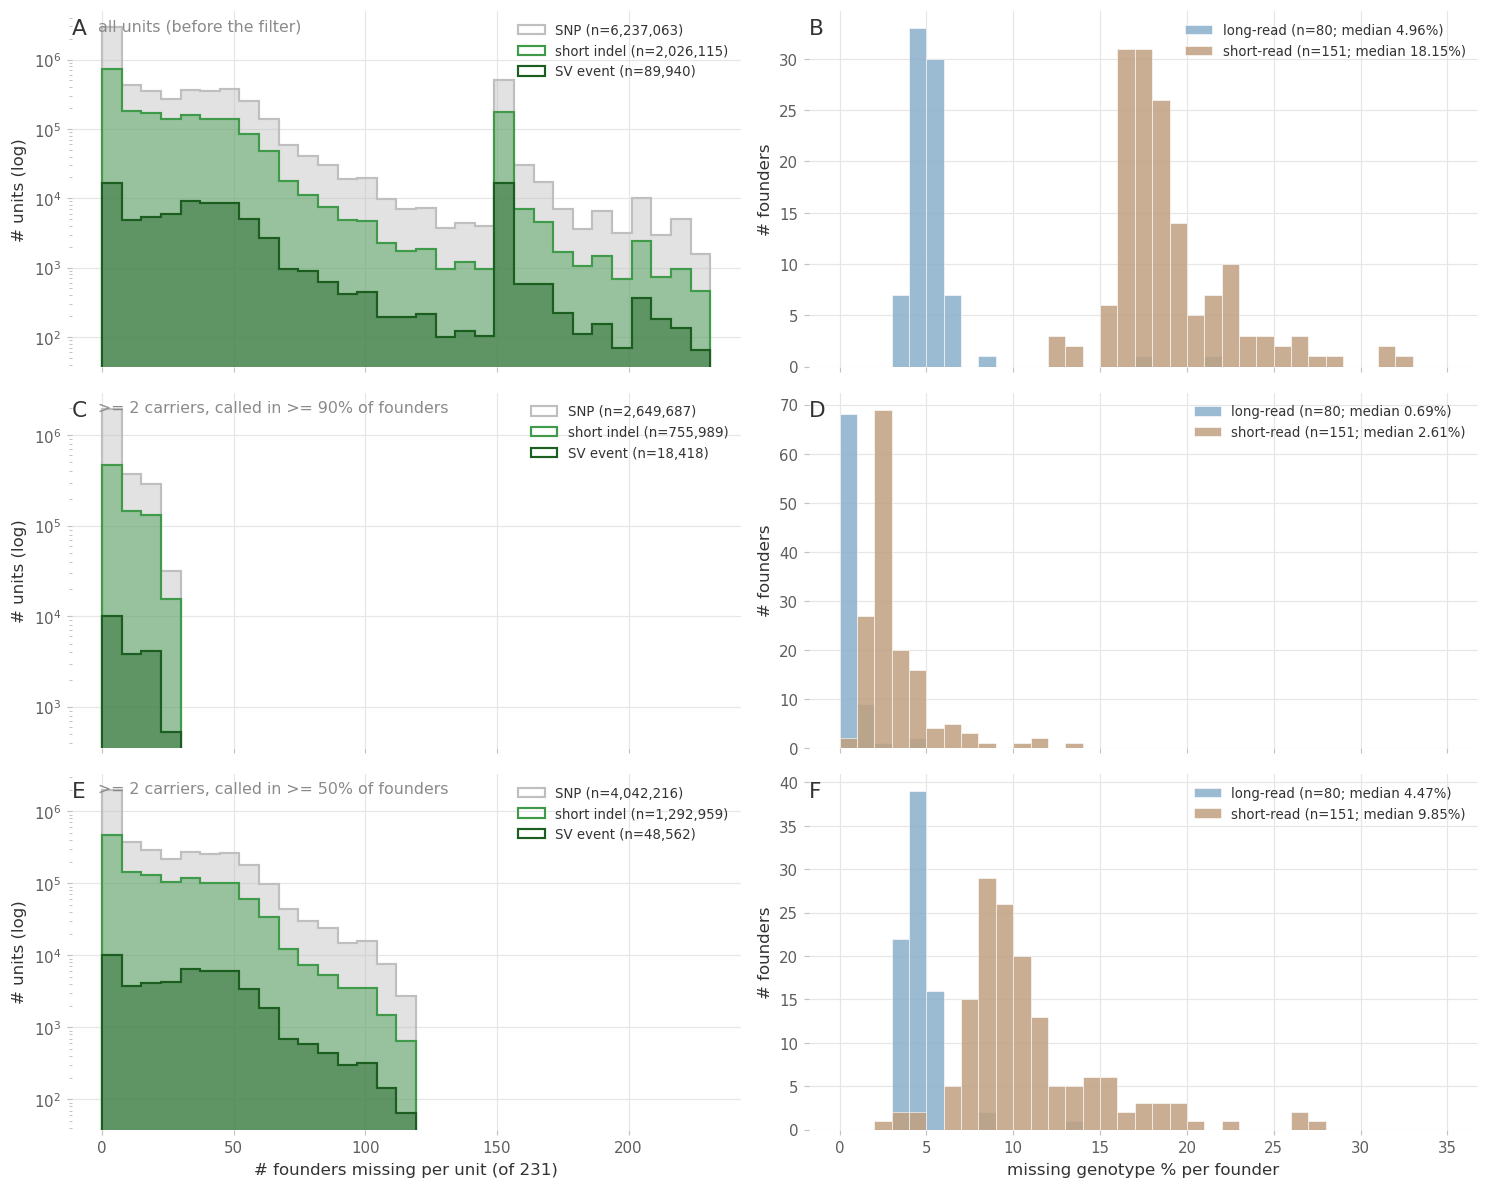

In [2]:

fig, axes = plt.subplots(3, 2, figsize=(12.5, 10), sharex='col')
xb = np.linspace(0, NF, 32); fb = np.arange(0, 36, 1.0)
for r, (s, lab) in enumerate(SETS):
    ax = axes[r, 0]
    for c, name, col in CLS:
        v = Z[f'miss_{s}_{c}']
        ax.hist(v, bins=xb, histtype='stepfilled', color=col, alpha=0.45, linewidth=0)
        ax.hist(v, bins=xb, histtype='step', color=col, linewidth=1.3, label=f"{name} (n={len(v):,})")
    ax.set_yscale('log'); ax.set_ylabel('# units (log)'); ax.legend(loc='upper right')
    TH.panel(ax, 'ABCDEF'[2*r], lab)
    ax = axes[r, 1]
    fc = Z[f'fcalled_{s}']; tot = int(Z[f'nunits_{s}'].sum()); miss = 100 * (1 - fc / tot)
    for coh, col in COH.items():
        sel = is_lr if coh == 'long-read' else ~is_lr
        ax.hist(miss[sel], bins=fb, color=col, alpha=0.85, edgecolor='white', linewidth=0.4,
                label=f"{coh} (n={int(sel.sum())}; median {np.median(miss[sel]):.2f}%)")
    ax.set_ylabel('# founders'); ax.legend(loc='upper right')
    TH.panel(ax, 'ABCDEF'[2*r+1])
axes[2, 0].set_xlabel(f"# founders missing per unit (of {NF})"); axes[2, 1].set_xlabel('missing genotype % per founder')
fig.tight_layout(); fig.savefig(f"{PLOTS}/05b_missingness_events_before_after.png", dpi=170); plt.show()


## Summary

In [3]:

t = []
for s, lab in SETS:
    fc = Z[f'fcalled_{s}']; tot = int(Z[f'nunits_{s}'].sum()); miss = 100 * (1 - fc / tot)
    d = dict(set=s, units=tot)
    for c, name, _ in CLS:
        v = Z[f'miss_{s}_{c}']; d[f'{name}: median missing founders'] = float(np.median(v))
    d['long-read founders, median % missing'] = round(float(np.median(miss[is_lr])), 2)
    d['short-read founders, median % missing'] = round(float(np.median(miss[~is_lr])), 2)
    t.append(d)
pd.DataFrame(t).set_index('set').round(2).T


set,all,cr90,cr50
units,8353118.00,3424094.00,5383737.00
SNP: median missing founders,10.00,2.00,8.00
short indel: median missing founders,20.00,4.00,17.00
SV event: median missing founders,40.00,6.00,32.00
"long-read founders, median % missing",4.96,0.69,4.47
"short-read founders, median % missing",18.15,2.61,9.85
